The code uses the code from youngsoul's pyimagesearch-covid19-image-classification: https://github.com/youngsoul/pyimagesearch-covid19-image-classification

it also uses the dataset from the COVID19, Pneumonia and Normal Chest X-ray PA Dataset: https://data.mendeley.com/datasets/mxc6vb7svm/2

this is to test the functionality of the code and the dataset.

In [ ]:
# cleans everything

%cd /content
#!rm -rf covid_pneumonia_dataset
!#rm -rf covid_pneumonia_dataset.zip
!#rm -rf covid_pneumonia_dataset_wrapped
!#rm -rf pyimagesearch-covid19-image-classification

/content


In [ ]:
# Get the classifier code from GitHub
%cd /content
!git clone https://github.com/MarzSaod/pyimagesearch-covid19-image-classification
REPO = "/content/pyimagesearch-covid19-image-classification"
%cd {REPO}
!mkdir -p models model_performance
%cd /content

/content
Cloning into 'pyimagesearch-covid19-image-classification'...
remote: Enumerating objects: 493, done.
remote: Counting objects: 100% (44/44), done.
remote: Compressing objects: 100% (38/38), done.
remote: Total 493 (delta 22), reused 17 (delta 6), pack-reused 449 (from 1)
Receiving objects: 100% (493/493), 789.71 MiB | 25.16 MiB/s, done.
Resolving deltas: 100% (65/65), done.
Updating files: 100% (394/394), done.
/content/pyimagesearch-covid19-image-classification
/content


In [ ]:
# Downloads the dataset directly into the environment and unzips the dataset
%cd /content

mendeley_link = "https://data.mendeley.com/public-api/zip/mxc6vb7svm/download/2"

!wget -O covid_pneumonia_dataset.zip "$mendeley_link"

import zipfile
import os

with zipfile.ZipFile('covid_pneumonia_dataset.zip') as z:
    z.extractall('covid_pneumonia_dataset')

for item in os.listdir('covid_pneumonia_dataset'):
    if item.endswith('.zip'):
        inner_path = os.path.join('covid_pneumonia_dataset', item)
        print(f"Found the dataset inside: {item}")
        with zipfile.ZipFile(inner_path) as inner_z:
            print(f"contains {len(inner_z.namelist())} items")
            inner_z.extractall('covid_pneumonia_dataset')
        os.remove(inner_path)


/content
--2026-10-06 00:37:44--  https://data.mendeley.com/public-api/zip/mxc6vb7svm/download/2
Resolving data.mendeley.com (data.mendeley.com)... 162.159.133.86, 162.159.130.86
Connecting to data.mendeley.com (data.mendeley.com)|162.159.133.86|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://prod-dcd-datasets-cache-zipfiles.s3.eu-west-1.amazonaws.com/mxc6vb7svm-2.zip?X-Amz-Security-Token=IQoJb3JpZ2luX2VjECEaCWV1LXdlc3QtMSJHMEUCIQDPsg5MyACMgQpdAlQcZlJJYEZJJ36aGU%2F4VTPOSTvMAgIgfljz3uNRvBFPKTonwVVUVUpkh0mkKJuBFokVY6Rzu8YqlQUI6P%2F%2F%2F%2F%2F%2F%2F%2F%2F%2FARAEGgwzNjcxNDczODM4MjUiDJrZeQOll1rjMjutLSrpBDya%2B9NDIGXoVukKdPIZSrDBMVtuyfaUrqTVH9hzc2iK%2FFw1oHRMifmwNNMQRKtfDHX7Q8yorDO0A%2FB5yCZ%2BMDNsRL2Gs2EyXchEEnXz4wB7RxMopVLoZtVDz7WkfBBfBnb9068tcKYnZ5gheKu8jn4V7DqIOhwsmD2BPUDLoZjkoEefeaheSoDfeoEGNsnIgIkh%2F6UGHIHV88TQZFicgPDCTjz0aziElbmlbsOD8LVsGXW1WkeDYvVu7Cll8dOVNEabjkqHGGHRtIB%2BFozLcP9uk12W3ArcIxiJS9mkHR8rS30We9ll8WrZQ0Jlu62Zae96NicvCxe5gU1zpADaqU3

In [ ]:
# to check the folders and image counts
import os

for root, dirs, files in os.walk("covid_pneumonia_dataset"):
    level = root.replace("covid_pneumonia_dataset", "").count(os.sep)
    indent = "  " * level
    print(f"{indent}{os.path.basename(root)}/  ({len(files)} files)")

covid_pneumonia_dataset/  (0 files)
  normal/  (2313 files)
  pneumonia/  (2313 files)
  covid/  (2313 files)


In [ ]:
# to update folder configuration to match the github code

import shutil

wrapped_root = '/content/covid_pneumonia_dataset_wrapped/all'
os.makedirs(wrapped_root, exist_ok=True)

for cls in ['covid', 'normal', 'pneumonia']:
    src = f'/content/covid_pneumonia_dataset/{cls}'
    dst = f'{wrapped_root}/{cls}'
    if os.path.exists(src):
        shutil.move(src, dst)

print("Data is ready at:", wrapped_root)


Data is ready at: /content/covid_pneumonia_dataset_wrapped/all


In [ ]:
import tensorflow as tf
print("GPU devices:", tf.config.list_physical_devices('GPU'))

GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


---
# New experiments: pneumonia recall
 one baseline run and one fine tuning run

In [ ]:
# Paths and helper code used by every cell below
import sys, importlib, os
from IPython.display import Image, display

DATASET = "/content/covid_pneumonia_dataset_wrapped/all"
OUT = f"{REPO}/outputs"          # results folder

# Safety checks

sys.path.insert(0, REPO)
import report_utils as ru
importlib.reload(ru)
print("Code is up to date. Results will be saved in:", OUT)

Code is up to date. Results will be saved in: /content/pyimagesearch-covid19-image-classification/outputs


## what image enhancement would

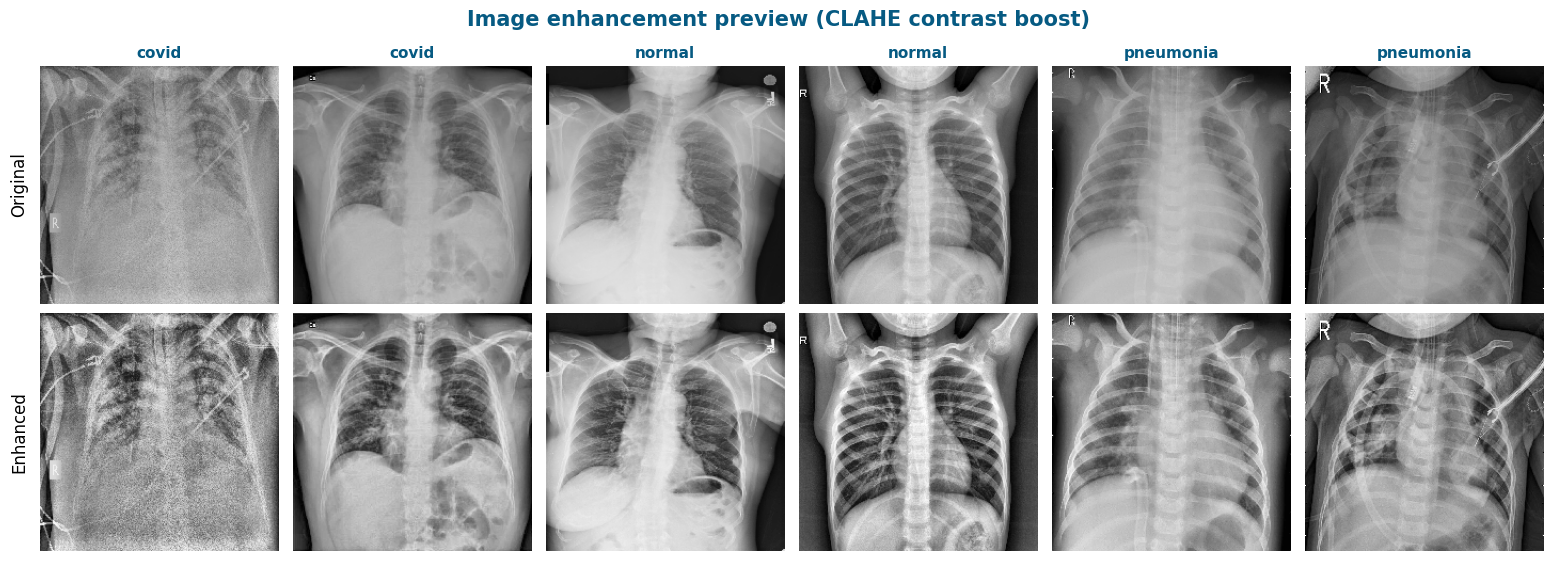

'clahe_preview.png'

In [ ]:
ru.clahe_preview(DATASET, n_per_class=2)

## Quick code test
Trains VGG16 for 2 epochs just to confirm nothing is broken.

In [ ]:
#%cd {REPO}
#!python train_covid19.py --dataset {DATASET} --models vgg16 --epochs 2 --run_name smoketest --outdir {OUT}

## Run 1: baseline VGG16
It saves the model, the prediction scores, and a one page report.

In [ ]:
%cd {REPO}
!python train_covid19.py --dataset {DATASET} --models vgg16 --epochs 25 --run_name baseline --outdir {OUT}

/content/pyimagesearch-covid19-image-classification
Running Train COVID19 Models
Using dataset directory: /content/covid_pneumonia_dataset_wrapped/all
---------------------------------------------------
Running Model: vgg16
Found 5523 images belonging to 3 classes.
Found 1379 images belonging to 3 classes.
Class Labels: ['covid', 'normal', 'pneumonia']
W0000 00:00:1791247189.299575    2859 gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was false.
58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
[INFO] compiling model...
[INFO] training...
Epoch 1/25

Epoch 1: val_accuracy improved from None to 0.71066, saving model to /content/pyimagesearch-covid19-image-classification/outputs/vgg16_baseline/best_model.h5

Epoch 1: finished saving model to /content/pyimagesearch-covid19-image-classification/outputs/vgg16_baseline/best_model.h5
691/691 - 194s - 281ms/step - accuracy: 0.7398 - loss: 0.6496 

## Baseline results: report, examples, and where the model looks

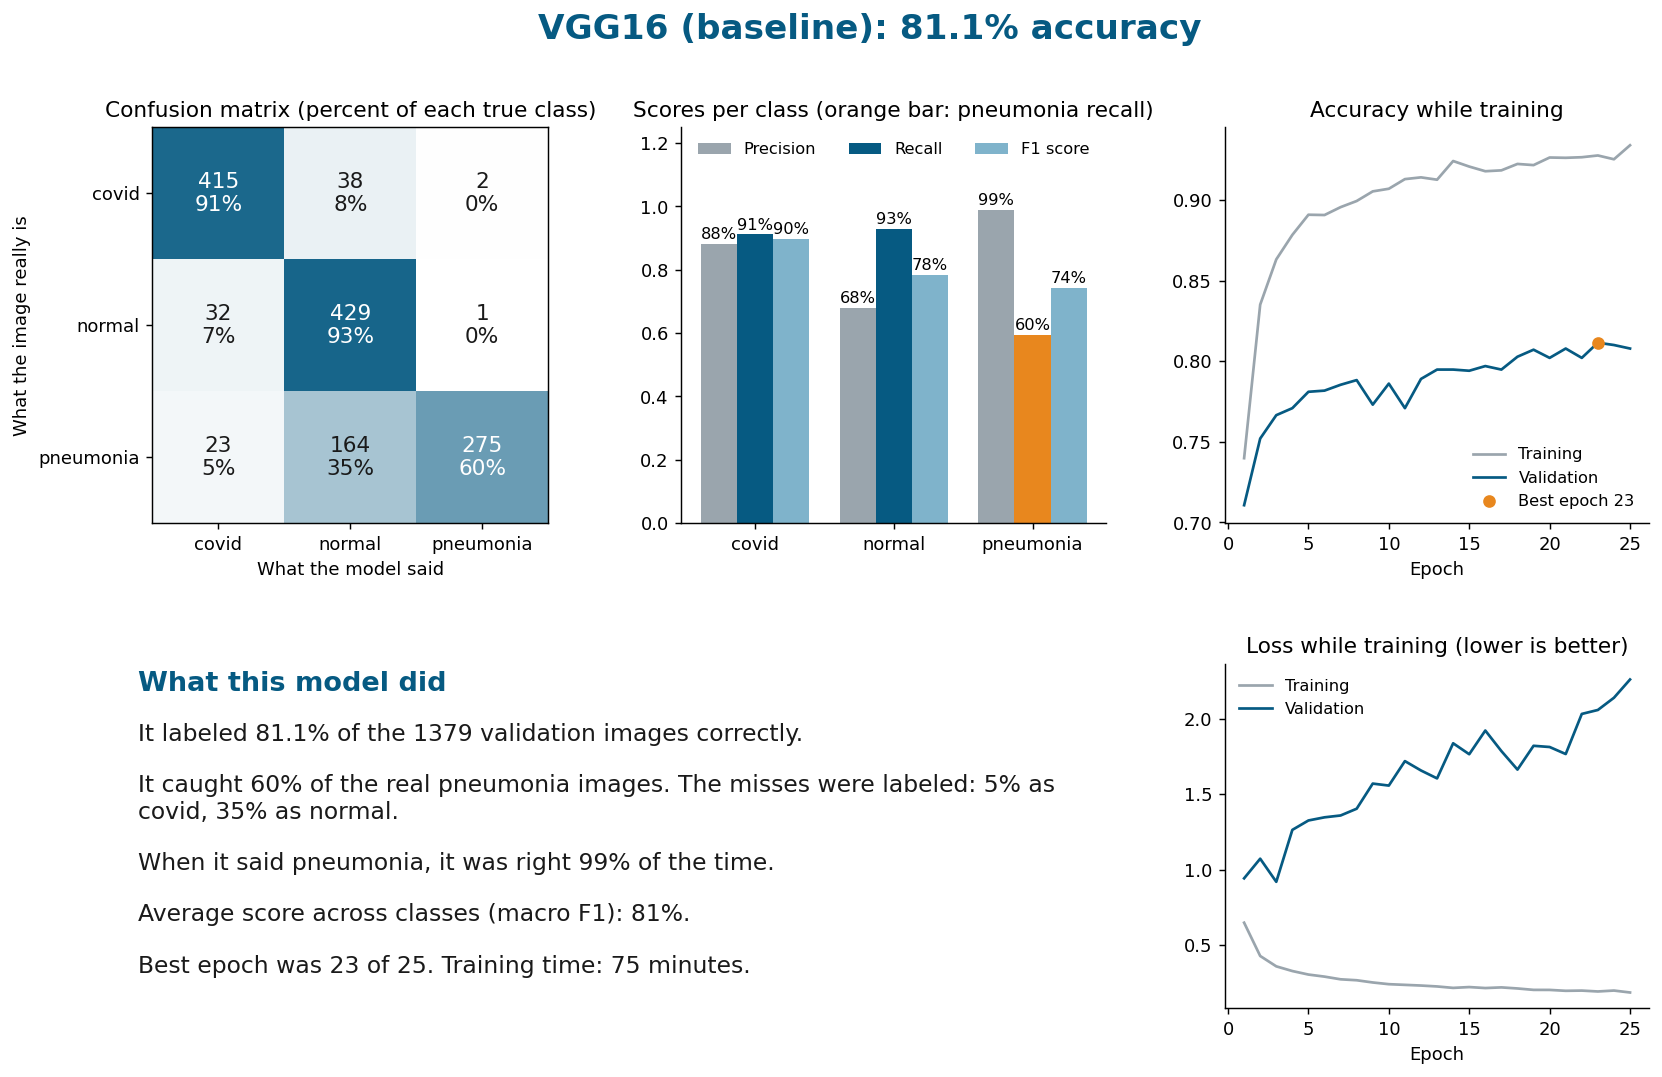

In [ ]:
RUN1 = f"{OUT}/vgg16_baseline"
display(Image(ru.make_model_report(RUN1)))

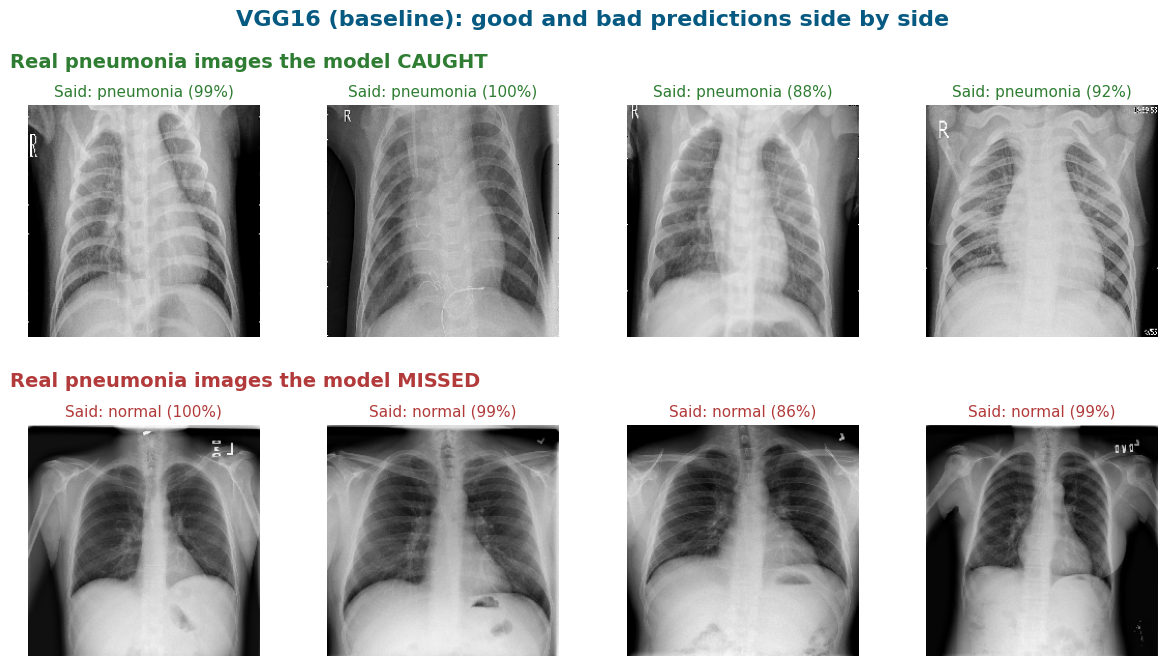

'/content/pyimagesearch-covid19-image-classification/outputs/vgg16_baseline/examples.png'

In [ ]:
# Real pneumonia images the model caught next to ones it missed
ru.show_predictions(RUN1, target_class="pneumonia", n=4)

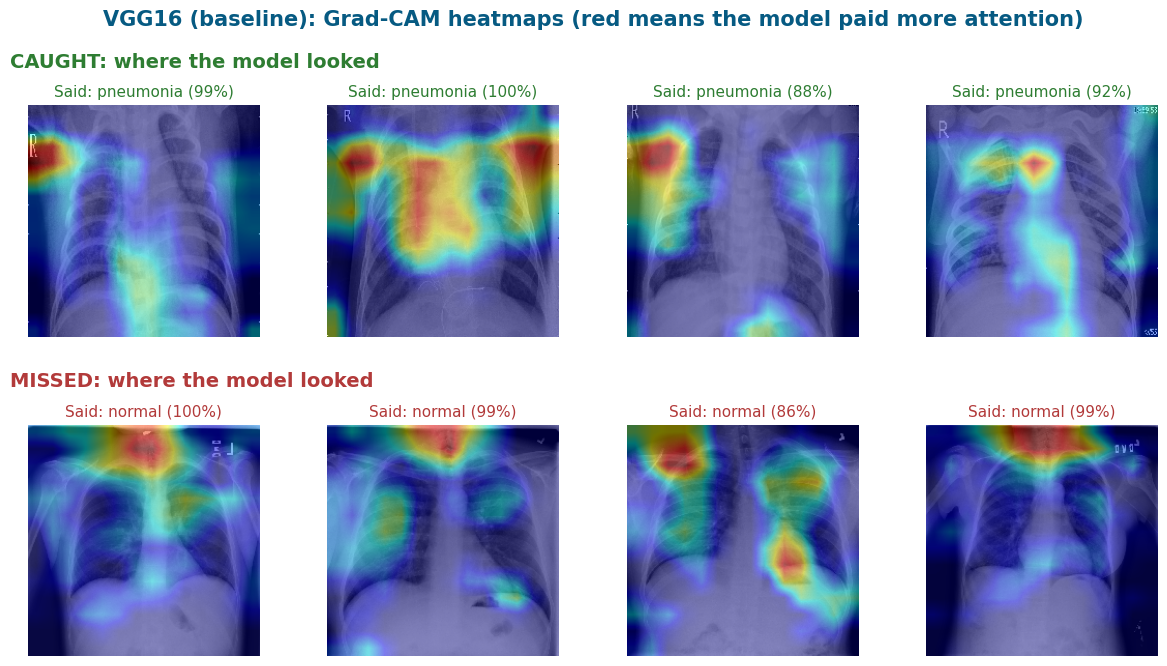

'/content/pyimagesearch-covid19-image-classification/outputs/vgg16_baseline/gradcam.png'

In [ ]:
# Grad-CAM: red areas are where the model paid the most attention
ru.gradcam_grid(RUN1, target_class="pneumonia", n=4)

## Experiment 1: make the model say pneumonia more easily
The bias is chosen on one half of the validation images and judged on the other half.

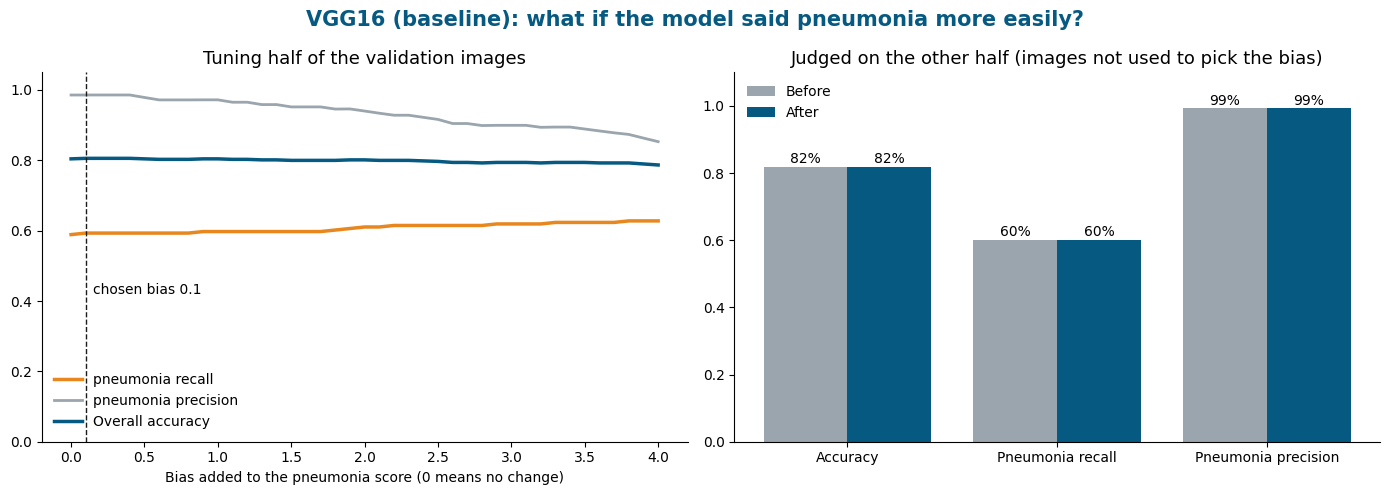

Chosen bias: 0.1


,Before (bias 0),After (bias 0.1)
Accuracy,81.9%,81.9%
Pneumonia recall,60.2%,60.2%
Pneumonia precision,99.3%,99.3%
Macro F1,81.6%,81.6%


In [ ]:
res = ru.threshold_analysis(RUN1, target_class="pneumonia")
print("Chosen bias:", res["best_bias"])
display(res["table"].style.format("{:.1%}"))

## Run 2: fine tune VGG16
Starts from the baseline model and unfreezes the last convolution block so it can learn X ray details.

In [ ]:
%cd {REPO}
!python train_covid19.py --dataset {DATASET} --models vgg16 --epochs 10 --run_name finetune --lr 1e-5 --init_from {RUN1}/best_model.h5 --outdir {OUT}

/content/pyimagesearch-covid19-image-classification
Running Train COVID19 Models
Using dataset directory: /content/covid_pneumonia_dataset_wrapped/all
---------------------------------------------------
Running Model: vgg16
Found 5523 images belonging to 3 classes.
Found 1379 images belonging to 3 classes.
Class Labels: ['covid', 'normal', 'pneumonia']
[INFO] loading starting model from /content/pyimagesearch-covid19-image-classification/outputs/vgg16_baseline/best_model.h5
W0000 00:00:1791251721.407613   23115 gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was false.
[INFO] unfroze 9 layers starting at block5_conv1
[INFO] compiling model...
[INFO] training...
Epoch 1/10

Epoch 1: val_accuracy improved from None to 0.81943, saving model to /content/pyimagesearch-covid19-image-classification/outputs/vgg16_finetune/best_model.h5

Epoch 1: finished saving model to /content/pyimagesearch-covid1

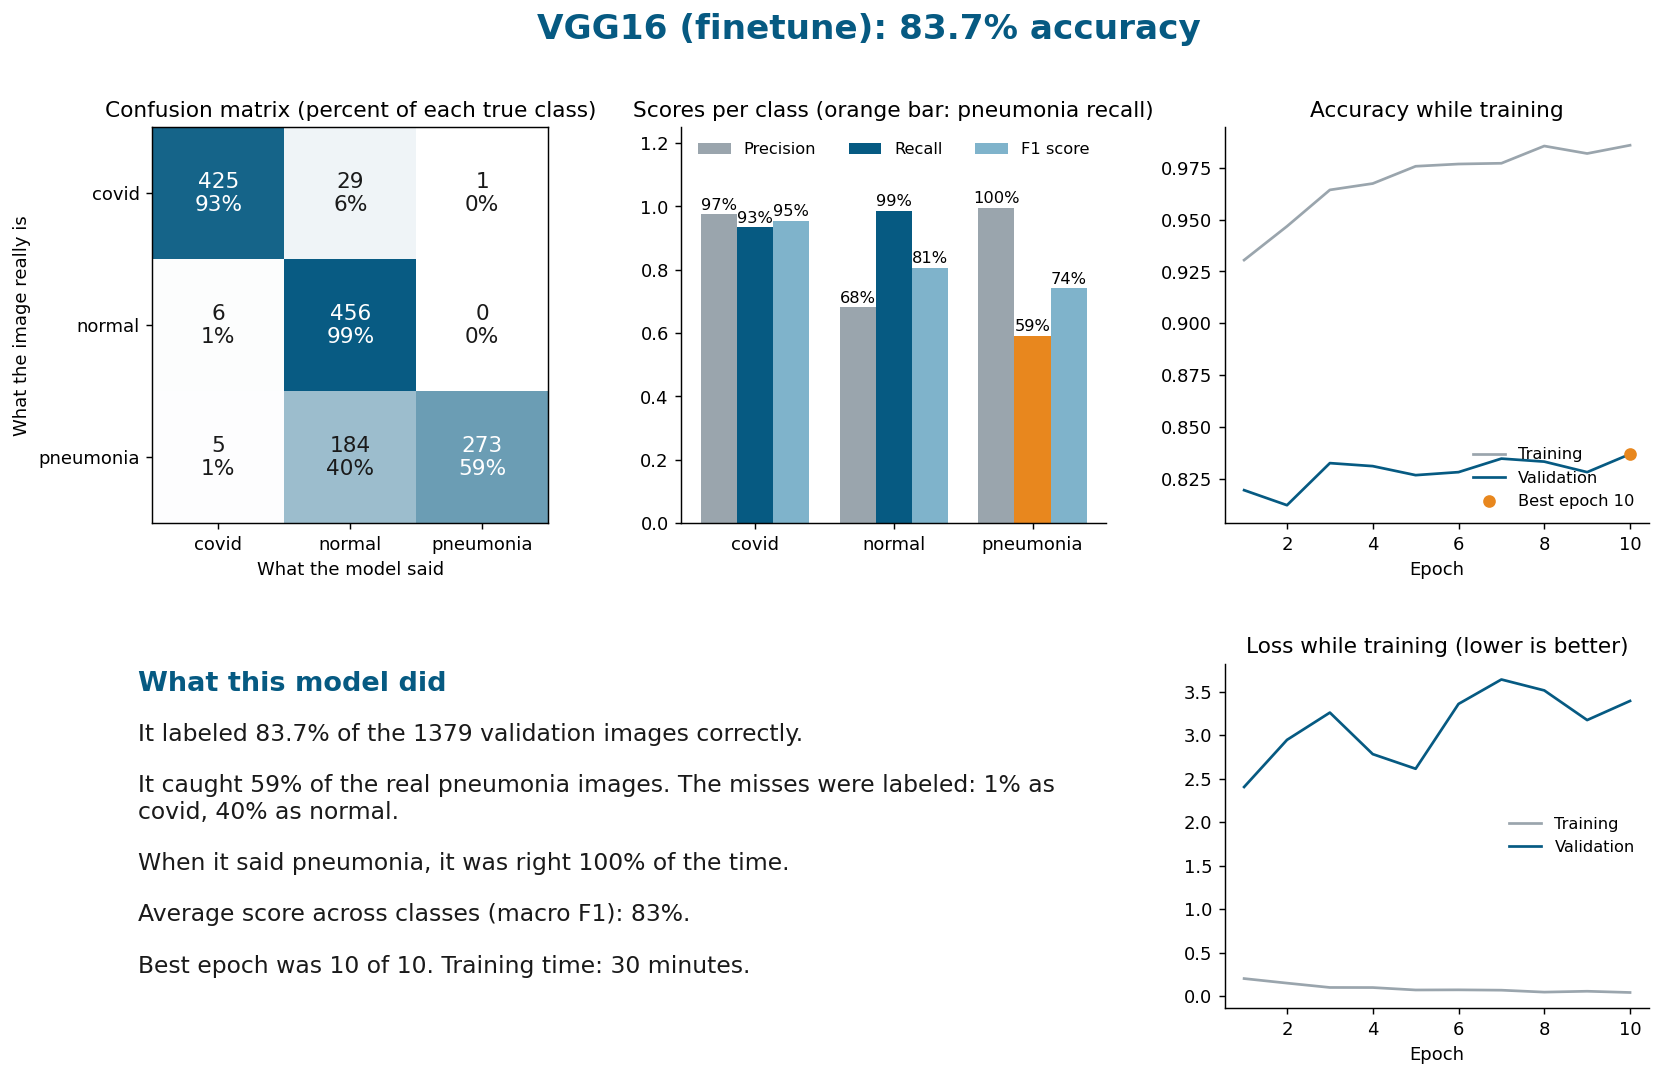

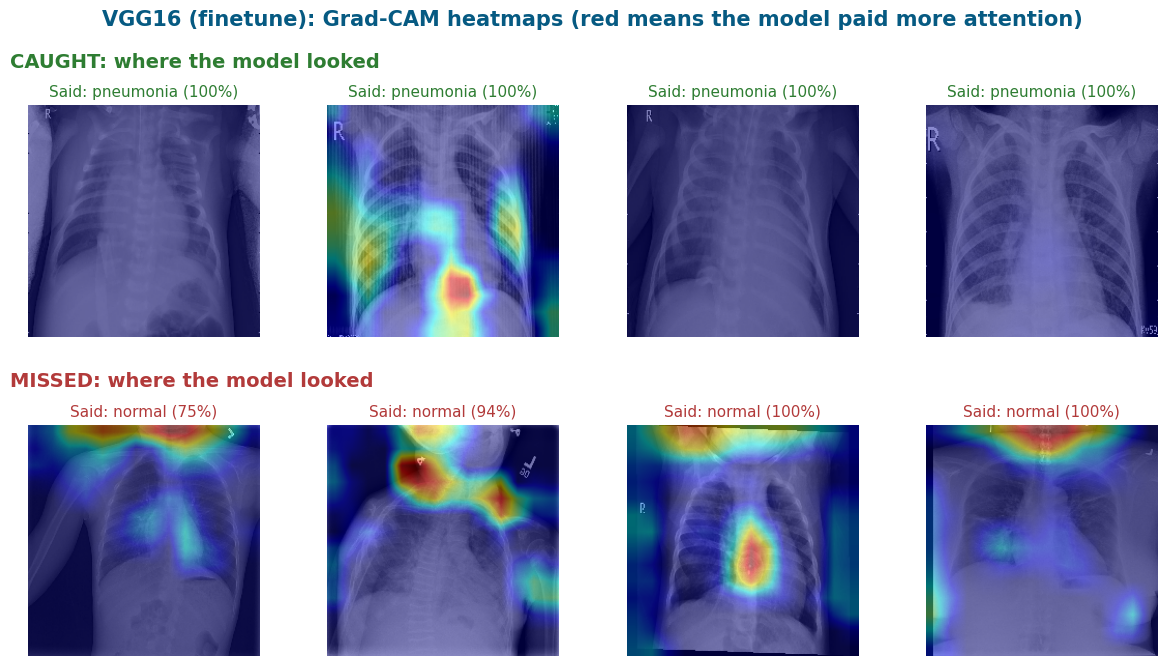

'/content/pyimagesearch-covid19-image-classification/outputs/vgg16_finetune/gradcam.png'

In [ ]:
RUN2 = f"{OUT}/vgg16_finetune"
display(Image(ru.make_model_report(RUN2)))
ru.gradcam_grid(RUN2, target_class="pneumonia", n=4)

## Final scoreboard: all runs side by side

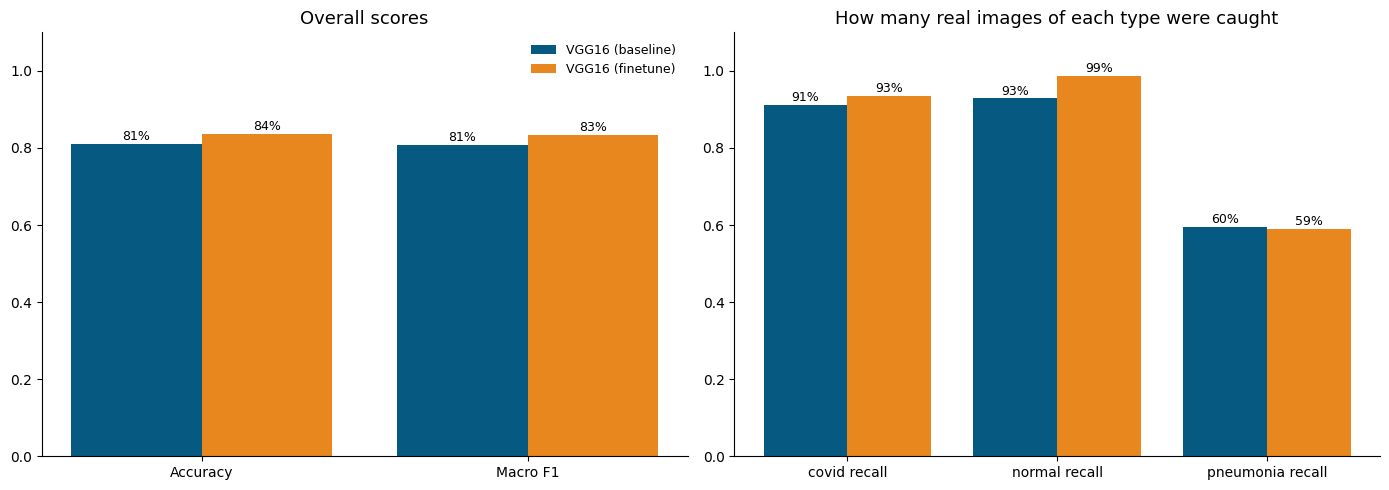

,Accuracy,Macro F1,Covid recall,Normal recall,Pneumonia recall,Pneumonia precision,Pneumonia called covid,Pneumonia called normal
Run,,,,,,,,
VGG16 (baseline),81.1%,80.9%,91.2%,92.9%,59.5%,98.9%,5.0%,35.5%
VGG16 (finetune),83.7%,83.4%,93.4%,98.7%,59.1%,99.6%,1.1%,39.8%


In [ ]:
df = ru.compare_runs(ru.find_runs(OUT))
display(df.style.format("{:.1%}").background_gradient(cmap="Blues", axis=None))

## Optional extra runs
- **Image enhancement:** adds the contrast boost you previewed above.
- **Original scaling:** feeds each pretrained model the pixel scaling it was originally trained with.

In [ ]:
%cd {REPO}
!python train_covid19.py --dataset {DATASET} --models vgg16 --epochs 25 --run_name clahe --clahe --outdir {OUT}
#!python train_covid19.py --dataset {DATASET} --models vgg16 --epochs 25 --run_name imagenetscale --preprocess imagenet --outdir {OUT}

## Download everything

In [ ]:
# Packs every report picture and result file (not the large model files) into one zip
!cd {OUT} && zip -r /content/results.zip . -x "*.h5"
from google.colab import files
files.download("/content/results.zip")

  adding: vgg16_finetune/ (stored 0%)
  adding: vgg16_finetune/class_labels.json (deflated 3%)
  adding: vgg16_finetune/history.json (deflated 50%)
  adding: vgg16_finetune/report.png (deflated 11%)
  adding: vgg16_finetune/val_files.json (deflated 94%)
  adding: vgg16_finetune/config.json (deflated 37%)
  adding: vgg16_finetune/val_probs.npy (deflated 15%)
  adding: vgg16_finetune/gradcam.png (deflated 1%)
  adding: vgg16_finetune/val_labels.npy (deflated 98%)
  adding: vgg16_baseline/ (stored 0%)
  adding: vgg16_baseline/class_labels.json (deflated 3%)
  adding: vgg16_baseline/history.json (deflated 53%)
  adding: vgg16_baseline/report.png (deflated 10%)
  adding: vgg16_baseline/examples.png (deflated 2%)
  adding: vgg16_baseline/val_files.json (deflated 94%)
  adding: vgg16_baseline/config.json (deflated 34%)
  adding: vgg16_baseline/threshold.png (deflated 13%)
  adding: vgg16_baseline/val_probs.npy (deflated 7%)
  adding: vgg16_baseline/gradcam.png (deflated 0%)
  adding: vgg16_ba

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---
## original runs

In [ ]:
# test run with only 2 epochs just to confirm nothing errors out
%cd {REPO}
!python train_covid19.py --dataset /content/covid_pneumonia_dataset_wrapped/all --epochs 2

/content/pyimagesearch-covid19-image-classification
Running Train COVID19 Models
Using dataset directory: /content/covid_pneumonia_dataset_wrapped/all
---------------------------------------------------
Running Model: vgg16
Found 5523 images belonging to 3 classes.
Found 1379 images belonging to 3 classes.
Class Labels: ['covid', 'normal', 'pneumonia']
W0000 00:00:1791253585.783769   31608 gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was false.
[INFO] compiling model...
[INFO] training...
Epoch 1/2

Epoch 1: val_accuracy improved from None to 0.71066, saving model to ./outputs/vgg16_baseline/best_model.h5

Epoch 1: finished saving model to ./outputs/vgg16_baseline/best_model.h5
691/691 - 187s - 271ms/step - accuracy: 0.7398 - loss: 0.6496 - val_accuracy: 0.7107 - val_loss: 0.9435
Epoch 2/2

Epoch 2: val_accuracy improved from 0.71066 to 0.75199, saving model to ./outputs/vgg16_baseline/be

In [ ]:
# run with 25 epochs
%cd {REPO}
!python train_covid19.py --dataset /content/covid_pneumonia_dataset_wrapped/all --epochs 25

/content/pyimagesearch-covid19-image-classification
Running Train COVID19 Models
Using dataset directory: /content/covid_pneumonia_dataset_wrapped/all
---------------------------------------------------
Running Model: vgg16
Found 5523 images belonging to 3 classes.
Found 1379 images belonging to 3 classes.
Class Labels: ['covid', 'normal', 'pneumonia']
W0000 00:00:1791254801.941488   37480 gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was false.
[INFO] compiling model...
[INFO] training...
Epoch 1/25

Epoch 1: val_accuracy improved from None to 0.71066, saving model to ./outputs/vgg16_baseline/best_model.h5

Epoch 1: finished saving model to ./outputs/vgg16_baseline/best_model.h5
691/691 - 188s - 273ms/step - accuracy: 0.7398 - loss: 0.6496 - val_accuracy: 0.7107 - val_loss: 0.9435
Epoch 2/25

Epoch 2: val_accuracy improved from 0.71066 to 0.75199, saving model to ./outputs/vgg16_baseline/